# Wrong-Wavelength Summary — P2 / P4 / P6 / Const-WL / True-Wavelength, one comparison per (dataset, decoder)

Combines five conditions that all keep pixel data and normalization untouched and only change the
*wavelength label* fed to each wavelength-conditioned encoder's hypernetwork:

| Old name | Used here as | What it does |
|---|---|---|
| — | **True λ (S2)** | Baseline: the regular benchmark's default wavelength label (Sentinel-2 band names/centers for every dataset, including the 3 cross-sensor ones below) |
| — | **True Wavelength** | SpaceNet7-CD / FiveBillionPixels / m-Forestnet only: each sensor's *own* real center wavelengths (PlanetScope / GaoFen-2 / Landsat-derived), replacing the S2-default label those datasets normally get |
| P2 | **Within-Group Shuffle** | Random permutation of labels *within* a spectral group (VIS / Red-Edge-NIR / SWIR), 2 draws averaged |
| P4 | **Full Random Shuffle** | Unconstrained random permutation of the whole wavelength vector, 3 draws averaged |
| P6 | **Fully Random λ** | Each band gets an independent Uniform(400,2500nm) draw, no relation to any real sensor band, 2 draws averaged |
| Const-WL | **Constant λ (550nm)** | Every band relabeled to the same uninformative wavelength -- most severe condition |

P1 (**Neighbor Swap**) is loaded but excluded from every plot in this notebook -- its Δ23-43nm swaps
between spectrally adjacent bands were too mild to read clearly here.

Encoders: DOFA, DOFA+ (DOFAv2), Panopticon, Copernicus-FM, **CARL** (the `carl_imagewise` variant --
imagewise normalization is the standard used everywhere in this project from P1 onward; plain
dataset-wise CARL is intentionally excluded), **SMARTIES**. ViT-p16-Frozen (a frozen, randomly-initialized
ViT with no wavelength conditioning at all) is loaded for reference but no longer plotted by default --
it only ever contributed a single flat baseline bar per chart, and dropping it frees up horizontal room
for the 6 encoders the ablation is actually about.

**SMARTIES's "Fully Random λ" (P6) bar is a discrete analog, not the literal condition.** Unlike the other
5 encoders, SMARTIES doesn't take a continuous wavelength value at all -- each band name is mapped through
a fixed lookup table onto one of ~18 discrete spectral-range projectors (see `smarties_encoder.py`).
P6's literal definition for the other encoders -- an unconstrained random float from Uniform(400,2500) --
has no direct equivalent SMARTIES can consume, so its P6 runs instead give each band an independent
*random projector index* (same two seeds/offsets as the continuous draws, rejection-sampled so no two
bands in one draw share a projector) -- each band "falls into a random bin" instead of a random
wavelength. Same spirit and same seeds as the other 5 encoders' P6, different (discrete) output space
forced by the architecture -- comparable in kind, not bit-for-bit identical in mechanism.

P2/P4 only exist for the UPerNet decoder (never run for MLP-Fusion). P6 and Const-WL exist for both
decoders (Const-WL also has a `cls_linear` variant for m-Forestnet). True-Wavelength only exists for the
3 cross-sensor datasets, both decoders (m-Forestnet's is decoder-agnostic `cls_linear`). One grouped bar
chart is produced per (dataset, decoder) combination that has baseline + at least one other condition
available.

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPERIMENTS_BASE = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments")

# ── Encoder display names (folder key -> display label) ─────────────────────
# carl_imagewise is CARL's standard/default variant here -- displayed simply as
# "CARL" (plain dataset-wise "carl" is intentionally left out entirely, same
# convention as the main results notebooks).
ENCODER_DISPLAY = {
    "dofa":               "DOFA",
    "dofav2":             "DOFA+",
    "copernicus_fm_base": "Copernicus-FM",
    "panopticon":         "Panopticon",
    "carl_imagewise":     "CARL",
    "smarties_vitb":      "SMARTIES",
}
# Bar order: DOFA, DOFA+, Copernicus-FM, Panopticon, CARL, SMARTIES.
# ViT-p16-Frozen (the random-init, no-wavelength-conditioning control) is still
# loaded below (all_rows) for anyone who wants it in code, but dropped from the
# default plotted set -- it only ever contributed one flat baseline bar per
# chart, and removing it frees up horizontal room for the 6 encoders that
# actually matter to this ablation.
# SMARTIES's "Fully Random λ" (P6) bar is a discrete analog -- see markdown
# above: it has no continuous wavelength input at all (fixed band-name ->
# discrete-projector lookup table), so its P6 runs use a random *projector
# index* per band (same seeds/offsets as the other 5 encoders' continuous
# draws) instead of a random float. Every condition (P2/P4/P6/Const-WL/True-WL
# /baseline) is present for it now.
ENCODER_ORDER = ["DOFA", "DOFA+", "Copernicus-FM", "Panopticon", "CARL", "SMARTIES"]

# Const-WL / True-Wavelength folders use short prefixes instead of the full encoder key
CONST_WL_SHORT = {
    "dofa": "dofa", "dofav2": "dofav2", "panopticon": "panopticon",
    "cfm": "copernicus_fm_base", "sm": "smarties_vitb",
    "carl_iw": "carl_imagewise",
}

# ── Dataset detection ─────────────────────────────────────────────────────────
DATASET_LABELS = {
    "mforestnet":         "m-Forestnet",
    "msa-crop-type":      "m-SA-Crop-Type",
    "mcashew-plantation": "m-Cashew-Plantation",
    "mados":              "MADOS",
    "hlsburnscars":       "HLS-BurnScars",
    "spacenet7cd":        "SpaceNet7-CD",
    "fivebillionpixels":  "FiveBillionPixels",
}
_DS_KEYS_SORTED = sorted(DATASET_LABELS, key=len, reverse=True)
DATASET_RE = re.compile(r"_(" + "|".join(re.escape(d) for d in _DS_KEYS_SORTED) + r")_")

METRIC_LABEL = {"m-Forestnet": "Accuracy (%)"}  # everything else defaults to mIoU

# "Neighbor Swap" (P1) is loaded (cell below) but intentionally excluded here --
# not part of CONDITION_ORDER, so plot_comparison() never shows it (its
# conditions list is always filtered against this). Order also fixes the bar
# order within every chart: True λ (S2) always first, True Wavelength (the
# "real"/correct wavelength for cross-sensor datasets) second, then the
# corruption conditions from mild to severe, Fully Random λ ("random" wavelength)
# last among those actually present for a given (dataset, decoder).
CONDITION_ORDER = [
    "True λ (S2)", "True Wavelength", "Within-Group Shuffle",
    "Full Random Shuffle", "Fully Random λ", "Constant λ (550nm)",
]

print("Config loaded.")

# ── Thesis plot style (LaTeX-adjacent, serif) ────────────────────────────────
# text.usetex=False: no local LaTeX installation on this cluster (verified --
# no `latex`/`pdflatex` binary on PATH). Setting it True would make every plot
# render crash. mathtext still renders Computer-Modern-like via matplotlib's
# built-in "cm" mathtext fontset, close to the intended LaTeX look.
# Font sizes bumped up a notch across the board (13/15/13/11/11/11) -- the
# original 11/11/11/9/9/9 set was too small to read comfortably once these
# plots got shrunk down for the thesis page.
# Color cycle: back to matplotlib's own default (tab10) -- no custom
# axes.prop_cycle override, unlike the colorblind-friendly 8-color cycle used
# elsewhere in this project.
GRID_COLOR = "#e3e2dd"
TEXT_MUTED = "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#c9c8c2",
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif"],  # CMR not installed here -- DejaVu Serif fallback
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.figsize": (6.0, 4.5),
    "figure.dpi": 150,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "axes.linewidth": 0.8,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

# Condition colors come from matplotlib's default color cycle (tab10),
# assigned positionally by CONDITION_ORDER.
_cycle_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
CONDITION_COLORS = {cond: _cycle_colors[i % len(_cycle_colors)] for i, cond in enumerate(CONDITION_ORDER)}

# ── Figure-save mechanism ────────────────────────────────────────────────────
# Every plot in this notebook saves itself to figures/ as a PDF (vector, safe
# for the thesis) alongside the on-screen display -- same convention as the
# sibling analyze_*.ipynb notebooks in this project.
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def _slug(text: str) -> str:
    """Filesystem-safe slug for figure filenames, e.g. 'm-Cashew-Plantation' -> 'm_cashew_plantation'."""
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")

Config loaded.


In [2]:
def parse_log_metrics(log_path: Path) -> dict:
    """Parse segmentation train.log-0 -- returns test_mIoU etc. (last [test] block)."""
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- IoU", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- IoU" + sections[-1]
    m = re.search(r"\[test\] ------- IoU.*?\[test\] Mean\s+([\d.]+)", test_block, re.DOTALL)
    return {"test_mIoU": float(m.group(1))} if m else {}


def parse_cls_log_metrics(log_path: Path) -> dict:
    """Parse classification train.log-0 -- returns test_Accuracy (last [test] block)."""
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- Accuracy", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- Accuracy" + sections[-1]
    m = re.search(r"\[test\] ------- Accuracy.*?\[test\] Mean\s+([\d.]+)", test_block, re.DOTALL)
    return {"test_Accuracy": float(m.group(1))} if m else {}


def load_folder_runs(folder: Path, encoder_disp: str, decoder_label: str, condition_label: str, draw=None) -> list[dict]:
    """Scan one experiment subfolder (already known encoder/condition/decoder) for run dirs, one row per dataset found.

    If a folder holds more than one run for the same dataset, the last one (by sorted
    run-dir name) wins rather than both being kept. Run-dir names are timestamp-prefixed,
    so this means a rerun supersedes a stale run instead of both later getting blended by
    the groupby-mean downstream -- same "last wins" convention as aggfunc="last" elsewhere
    in this project. This matters concretely for the True-Wavelength SpaceNet7-CD runs,
    which were rerun after the dice-loss collapse fix and left the old run directories in
    place alongside the fixed reruns.
    """
    if not folder.exists():
        return []
    by_dataset: dict[str, dict] = {}
    for run_dir in sorted(folder.iterdir()):
        if not run_dir.is_dir():
            continue
        m = DATASET_RE.search(run_dir.name)
        if not m:
            continue
        ds_raw = m.group(1)
        ds_label = DATASET_LABELS[ds_raw]
        log = run_dir / "train.log-0"
        if ds_raw == "mforestnet":
            v = parse_cls_log_metrics(log).get("test_Accuracy")
            val = v * 100 if v is not None else None
        else:
            val = parse_log_metrics(log).get("test_mIoU")
        if val is None:
            continue
        # m-Forestnet is always a decoder-agnostic linear probe (cls_linear) --
        # override whatever decoder label this experiment folder normally uses.
        dec_label = "Linear-Classification" if ds_raw == "mforestnet" else decoder_label
        by_dataset[ds_label] = dict(encoder=encoder_disp, dataset=ds_label, decoder=dec_label,
                                     condition=condition_label, draw=draw, metric=val, run_dir=run_dir.name)
    return list(by_dataset.values())


print("Parse/load functions defined.")

Parse/load functions defined.


In [3]:
P1_BASE  = EXPERIMENTS_BASE / "p1_wlswap_ablation"
P2_BASE  = EXPERIMENTS_BASE / "p2_wlswap_ablation"
P4_BASE  = EXPERIMENTS_BASE / "p4_wlswap_ablation"
P6_MLP_BASE = EXPERIMENTS_BASE / "p6_random_wl_ablation"
P6_UP_BASE  = EXPERIMENTS_BASE / "p6_random_wl_ablation_upernet"
CONST_WL_BASE = EXPERIMENTS_BASE / "wavelength_ablation_const_wl"

PANGAEA_UP_BASE  = EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet"
PANGAEA_MLP_BASE = EXPERIMENTS_BASE / "pangaea_full_seg" / "mlp_fusion"
GEOBENCH_UP_BASE  = EXPERIMENTS_BASE / "geobench" / "seg" / "UPerNet"
GEOBENCH_MLP_BASE = EXPERIMENTS_BASE / "geobench" / "seg" / "MLPFusion"
GEOBENCH_CLS_BASE = EXPERIMENTS_BASE / "geobench" / "cls"

all_rows = []

# ── P1 -- Neighbor Swap (UPerNet only, single run, no draws) ────────────────
for enc_key, enc_disp in ENCODER_DISPLAY.items():
    all_rows += load_folder_runs(P1_BASE / enc_key, enc_disp, "UPerNet", "Neighbor Swap")

# ── P2 -- Within-Group Shuffle (UPerNet only, 2 draws) ───────────────────────
for enc_key, enc_disp in ENCODER_DISPLAY.items():
    for draw in ["A", "B"]:
        all_rows += load_folder_runs(P2_BASE / f"{enc_key}_draw{draw}", enc_disp, "UPerNet",
                                      "Within-Group Shuffle", draw=draw)

# ── P4 -- Full Random Shuffle (UPerNet only, 3 draws) ────────────────────────
for enc_key, enc_disp in ENCODER_DISPLAY.items():
    for draw in ["1", "2", "3"]:
        all_rows += load_folder_runs(P4_BASE / f"{enc_key}_draw{draw}", enc_disp, "UPerNet",
                                      "Full Random Shuffle", draw=draw)

# ── P6 -- Fully Random \u03bb (MLP-Fusion: 3 draws, UPerNet: 2 draws) ───────
for enc_key, enc_disp in ENCODER_DISPLAY.items():
    for draw in ["1", "2", "3"]:
        all_rows += load_folder_runs(P6_MLP_BASE / f"{enc_key}_draw{draw}", enc_disp, "MLP-Fusion",
                                      "Fully Random \u03bb", draw=draw)
    for draw in ["1", "2"]:
        all_rows += load_folder_runs(P6_UP_BASE / f"{enc_key}_draw{draw}", enc_disp, "UPerNet",
                                      "Fully Random \u03bb", draw=draw)

# ── Const-WL -- Constant \u03bb (550nm), 3 decoder variants ─────────────────
CONST_WL_DECODER = {"up": "UPerNet", "mlp": "MLP-Fusion", "cls": "Linear-Classification"}
for short, enc_key in CONST_WL_SHORT.items():
    enc_disp = ENCODER_DISPLAY[enc_key]
    for suffix, dec_label in CONST_WL_DECODER.items():
        all_rows += load_folder_runs(CONST_WL_BASE / f"{short}_const_wl_{suffix}", enc_disp, dec_label,
                                      "Constant \u03bb (550nm)")

print(f"{len(all_rows)} rows loaded across P1/P2/P4/P6/Const-WL.")

342 rows loaded across P1/P2/P4/P6/Const-WL.


In [4]:
# ── True Wavelength -- SpaceNet7-CD / FiveBillionPixels / m-Forestnet only ──
# These 3 cross-sensor datasets (PlanetScope / GaoFen-2 / Landsat-derived) get
# their bands labeled with the nearest Sentinel-2 band name as a convenience
# default everywhere else in this notebook -- that default is what "True λ (S2)"
# measures for them too. This dedicated ablation instead feeds each sensor's own
# real center wavelengths into the hypernetwork (pixels and labels unchanged).
TRUE_WL_UP_BASE  = EXPERIMENTS_BASE / "wavelength_ablation"
TRUE_WL_MLP_BASE = EXPERIMENTS_BASE / "wavelength_ablation_mlpfusion"
SHORT_BY_ENC_KEY = {v: k for k, v in CONST_WL_SHORT.items()}

for enc_key, enc_disp in ENCODER_DISPLAY.items():
    short = SHORT_BY_ENC_KEY[enc_key]
    all_rows += load_folder_runs(TRUE_WL_UP_BASE / f"{short}_wl_ablation", enc_disp, "UPerNet", "True Wavelength")
    all_rows += load_folder_runs(TRUE_WL_MLP_BASE / f"{short}_wl_ablation", enc_disp, "MLP-Fusion", "True Wavelength")

print(f"{len(all_rows)} rows loaded across P1/P2/P4/P6/Const-WL/True-Wavelength.")

372 rows loaded across P1/P2/P4/P6/Const-WL/True-Wavelength.


In [5]:
# ── Baselines (True λ / S2) -- regular benchmark + GeoBench sources ────
BASELINE_UP_FOLDER  = {k: f"{k}_seg" for k in ENCODER_DISPLAY}
BASELINE_MLP_FOLDER = {k: f"{k}_mlp_fusion" for k in ENCODER_DISPLAY}

for enc_key, enc_disp in ENCODER_DISPLAY.items():
    all_rows += load_folder_runs(PANGAEA_UP_BASE / BASELINE_UP_FOLDER[enc_key], enc_disp, "UPerNet", "True λ (S2)")
    all_rows += load_folder_runs(PANGAEA_MLP_BASE / BASELINE_MLP_FOLDER[enc_key], enc_disp, "MLP-Fusion", "True λ (S2)")
    all_rows += load_folder_runs(GEOBENCH_UP_BASE / enc_key, enc_disp, "UPerNet", "True λ (S2)")
    all_rows += load_folder_runs(GEOBENCH_MLP_BASE / enc_key, enc_disp, "MLP-Fusion", "True λ (S2)")
    all_rows += load_folder_runs(GEOBENCH_CLS_BASE / enc_key, enc_disp, "Linear-Classification", "True λ (S2)")

# ── ViT-p16-Frozen reference (no wavelength conditioning -- baseline only) ──
all_rows += load_folder_runs(PANGAEA_UP_BASE / "vit_scratch_frozen_encoder_seg", "ViT-p16-Frozen", "UPerNet", "True λ (S2)")
all_rows += load_folder_runs(PANGAEA_MLP_BASE / "vit_scratch_frozen_encoder_mlp_fusion", "ViT-p16-Frozen", "MLP-Fusion", "True λ (S2)")
all_rows += load_folder_runs(GEOBENCH_UP_BASE / "vit_frozen_p16", "ViT-p16-Frozen", "UPerNet", "True λ (S2)")
all_rows += load_folder_runs(GEOBENCH_MLP_BASE / "vit_frozen_p16", "ViT-p16-Frozen", "MLP-Fusion", "True λ (S2)")
all_rows += load_folder_runs(GEOBENCH_CLS_BASE / "vit_frozen_p16", "ViT-p16-Frozen", "Linear-Classification", "True λ (S2)")

df_all = pd.DataFrame(all_rows)
print(f"{len(df_all)} rows total (incl. baselines + ViT-p16-Frozen reference).")

# Average over draws (P2/P4/P6) so each (encoder, dataset, decoder, condition) has one value
df_agg = df_all.groupby(["encoder", "dataset", "decoder", "condition"], as_index=False)["metric"].mean()
print(f"{len(df_agg)} rows after averaging draws.")

463 rows total (incl. baselines + ViT-p16-Frozen reference).
313 rows after averaging draws.


## Coverage check -- which (dataset, decoder) combos have data for which conditions

In [6]:
coverage = (
    df_agg[df_agg["encoder"] != "ViT-p16-Frozen"]
    .pivot_table(index=["dataset", "decoder"], columns="condition", values="metric", aggfunc="count")
    .reindex(columns=[c for c in CONDITION_ORDER])
)
coverage

condition                                  True λ (S2)  True Wavelength  \
dataset             decoder                                               
FiveBillionPixels   MLP-Fusion                     6.0              6.0   
                    UPerNet                        6.0              6.0   
HLS-BurnScars       MLP-Fusion                     6.0              NaN   
                    UPerNet                        6.0              NaN   
MADOS               MLP-Fusion                     6.0              NaN   
                    UPerNet                        6.0              NaN   
SpaceNet7-CD        MLP-Fusion                     6.0              6.0   
                    UPerNet                        6.0              6.0   
m-Cashew-Plantation MLP-Fusion                     6.0              NaN   
                    UPerNet                        6.0              NaN   
m-Forestnet         Linear-Classification          6.0              6.0   
m-SA-Crop-Type      MLP-Fusion                     6.0              NaN   
                    UPerNet                        6.0              NaN   

condition                                  Within-Group Shuffle  \
dataset             decoder                                       
FiveBillionPixels   MLP-Fusion                              NaN   
                    UPerNet                                 NaN   
HLS-BurnScars       MLP-Fusion                              NaN   
                    UPerNet                                 NaN   
MADOS               MLP-Fusion                              NaN   
                    UPerNet                                 6.0   
SpaceNet7-CD        MLP-Fusion                              NaN   
                    UPerNet                                 NaN   
m-Cashew-Plantation MLP-Fusion                              NaN   
                    UPerNet                                 6.0   
m-Forestnet         Linear-Classification                   6.0   
m-SA-Crop-Type      MLP-Fusion                              NaN   
                    UPerNet                                 6.0   

condition                                  Full Random Shuffle  \
dataset             decoder                                      
FiveBillionPixels   MLP-Fusion                             NaN   
                    UPerNet                                NaN   
HLS-BurnScars       MLP-Fusion                             NaN   
                    UPerNet                                NaN   
MADOS               MLP-Fusion                             NaN   
                    UPerNet                                6.0   
SpaceNet7-CD        MLP-Fusion                             NaN   
                    UPerNet                                NaN   
m-Cashew-Plantation MLP-Fusion                             NaN   
                    UPerNet                                6.0   
m-Forestnet         Linear-Classification                  6.0   
m-SA-Crop-Type      MLP-Fusion                             NaN   
                    UPerNet                                6.0   

condition                                  Fully Random λ  Constant λ (550nm)  
dataset             decoder                                                    
FiveBillionPixels   MLP-Fusion                        6.0                 NaN  
                    UPerNet                           6.0                 NaN  
HLS-BurnScars       MLP-Fusion                        NaN                 6.0  
                    UPerNet                           NaN                 6.0  
MADOS               MLP-Fusion                        6.0                 6.0  
                    UPerNet                           6.0                 6.0  
SpaceNet7-CD        MLP-Fusion                        6.0                 NaN  
                    UPerNet                           6.0                 NaN  
m-Cashew-Plantation MLP-Fusion                        6.0                 6.0

## How the "Fully Random λ" (P6) wavelengths were drawn

Each band gets an independent draw from **Uniform(400, 2500) nm** -- the range spanning Sentinel-2's
VIS/NIR/SWIR bands and beyond, with *no* relationship to that band's real center wavelength (unlike
P1/P2/P4/Const-WL, which all still start from the real S2 vector and swap/shuffle/flatten it). Two seeded
draws are used (seed 501 / seed 502, each with a per-dataset offset so e.g. MADOS and m-Forestnet don't
draw correlated values from the "same" seed), and every plot in this notebook averages over both. Values
are rejection-sampled: redraw until every pair of wavelengths within one band vector is at least 5nm
apart -- a degeneracy guard against two bands accidentally landing on (almost) the same label, not a
physical constraint.

The panel below shows exactly where each band's label landed for both draws, per dataset-band-group --
solid line from the band's real center wavelength (left) to its random draw (right).

saved figures/wrong_wl_summary_p6_band_movement.pdf


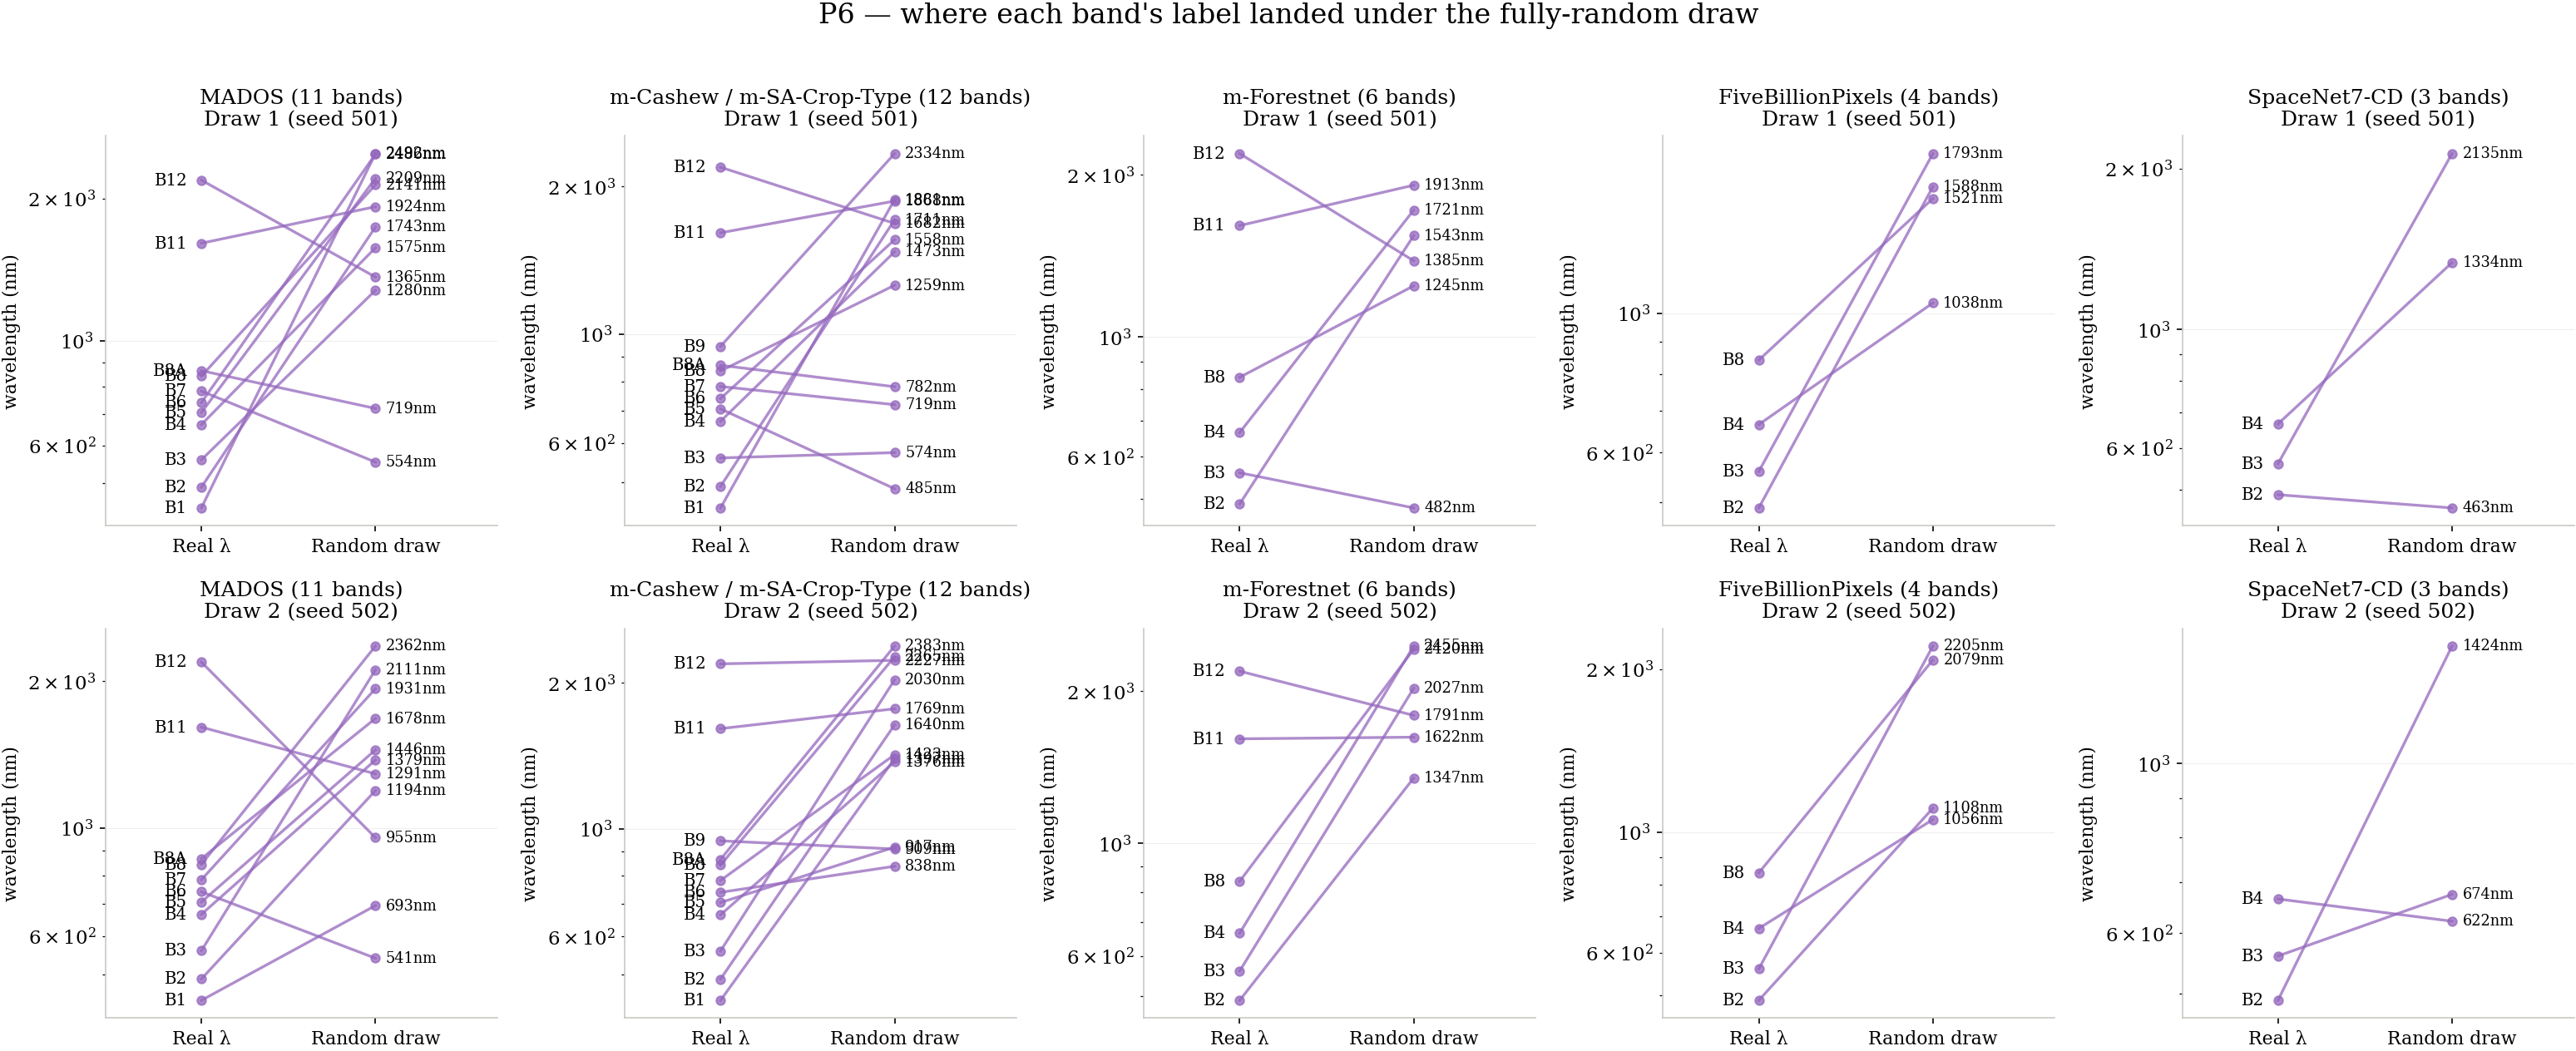

In [7]:
import json as _json

with open("../scripts/slurm_scripts/wavelength_ablation/p6_random_wl_draws.json") as f:
    p6_manifest = _json.load(f)

REF_WL_NM = {
    "B1": 443, "B2": 490, "B3": 560, "B4": 665, "B5": 705, "B6": 740, "B7": 783,
    "B8": 842, "B8A": 865, "B9": 945, "B11": 1610, "B12": 2190,
}
ORDER_MADOS = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
ORDER_12B   = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12"]
ORDER_MFN   = ["B2", "B3", "B4", "B8", "B11", "B12"]
ORDER_SN7CD = ["B4", "B3", "B2"]
ORDER_FBP   = ["B8", "B4", "B3", "B2"]


def plot_p6_random_panel(ax, dsgroup, draw, order, title):
    vals = p6_manifest["sampled_values_nm"][draw][dsgroup]
    for b in order:
        y0, y1 = REF_WL_NM[b], vals[b]
        ax.plot([0, 1], [y0, y1], color=CONDITION_COLORS["Fully Random λ"], alpha=0.75,
                linewidth=1.6, marker="o", markersize=5, zorder=3)
        ax.annotate(b, (0, y0), textcoords="offset points", xytext=(-8, 0), ha="right", va="center", fontsize=9.5)
        ax.annotate(f"{y1:.0f}nm", (1, y1), textcoords="offset points", xytext=(6, 0),
                     ha="left", va="center", fontsize=8.5)
    ax.set_yscale("log")
    ax.set_xlim(-0.55, 1.7)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Real λ", "Random draw"], fontsize=10.5)
    ax.set_ylabel("wavelength (nm)", fontsize=10.5)
    ax.set_title(title, fontsize=12)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)


groups = [
    ("mados",  ORDER_MADOS, "MADOS (11 bands)"),
    ("s2_12b", ORDER_12B,   "m-Cashew / m-SA-Crop-Type (12 bands)"),
    ("mfn",    ORDER_MFN,   "m-Forestnet (6 bands)"),
    ("fbp",    ORDER_FBP,   "FiveBillionPixels (4 bands)"),
    ("sn7cd",  ORDER_SN7CD, "SpaceNet7-CD (3 bands)"),
]
fig, axes = plt.subplots(2, len(groups), figsize=(4.2 * len(groups), 8.5))
for col, (dsgroup, order, label) in enumerate(groups):
    plot_p6_random_panel(axes[0, col], dsgroup, "1", order, f"{label}\nDraw 1 (seed 501)")
    plot_p6_random_panel(axes[1, col], dsgroup, "2", order, f"{label}\nDraw 2 (seed 502)")
fig.suptitle("P6 — where each band's label landed under the fully-random draw", fontsize=16, y=1.01)
fig.tight_layout()

_p6_fname = "wrong_wl_summary_p6_band_movement.pdf"
fig.savefig(FIG_DIR / _p6_fname, bbox_inches="tight")
print(f"saved {FIG_DIR / _p6_fname}")

plt.show()

## Comparison plots -- one grouped bar chart per (dataset, decoder)

The last five combos below (m-Forestnet, FiveBillionPixels ×2 decoders, SpaceNet7-CD ×2 decoders) carry
an extra **True Wavelength** bar: these are the only 3 datasets where the S2-default label used
everywhere else in this notebook isn't actually correct, so they get a genuine three-way comparison --
**True λ (S2)** vs. **Fully Random λ** vs. **True Wavelength** -- while the native-S2 datasets only ever
have the baseline vs. corruption conditions.

saved figures/wrong_wl_summary_mados_upernet.pdf


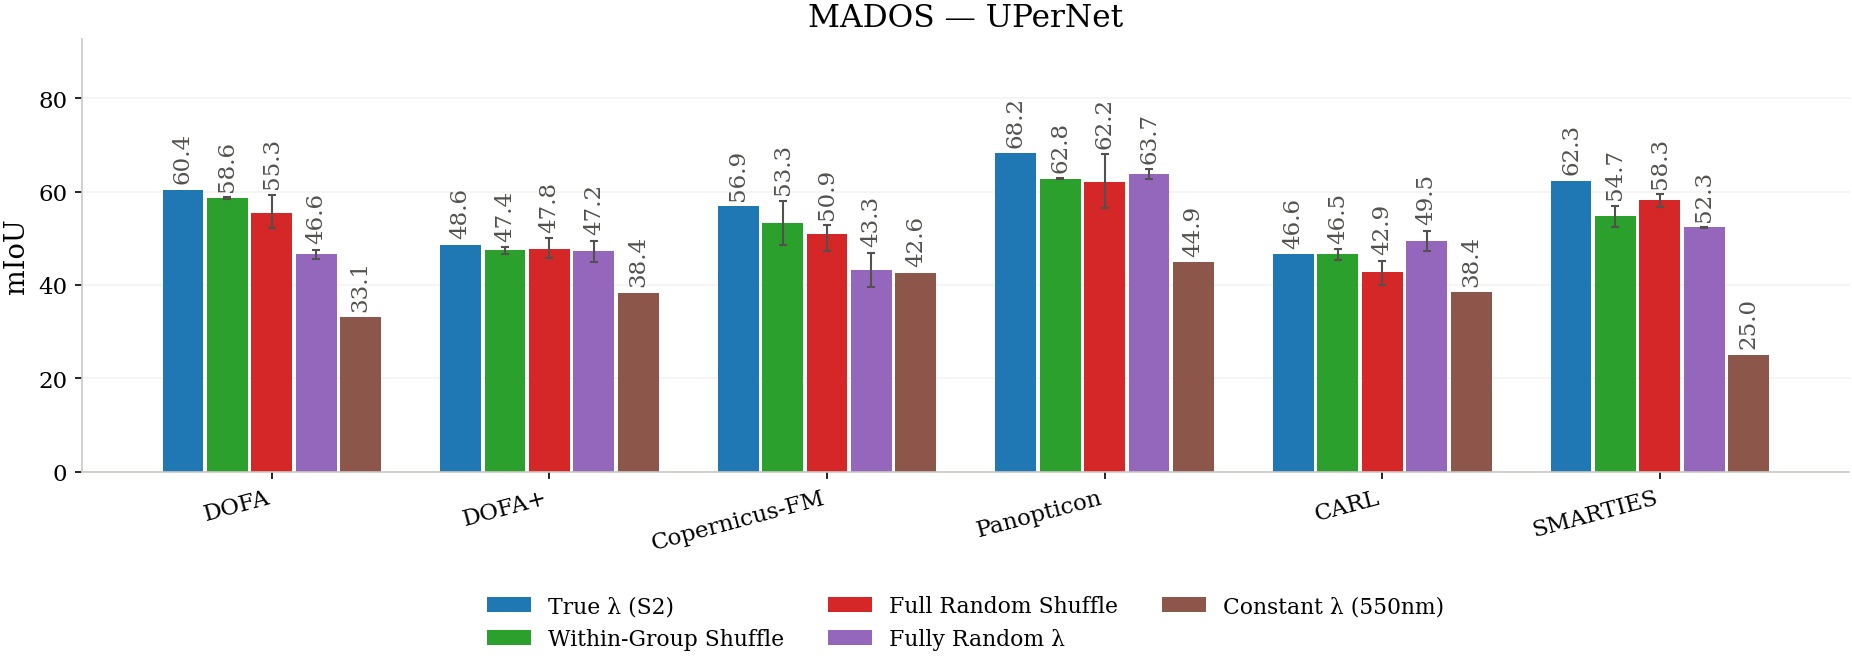

saved figures/wrong_wl_summary_m_cashew_plantation_upernet.pdf


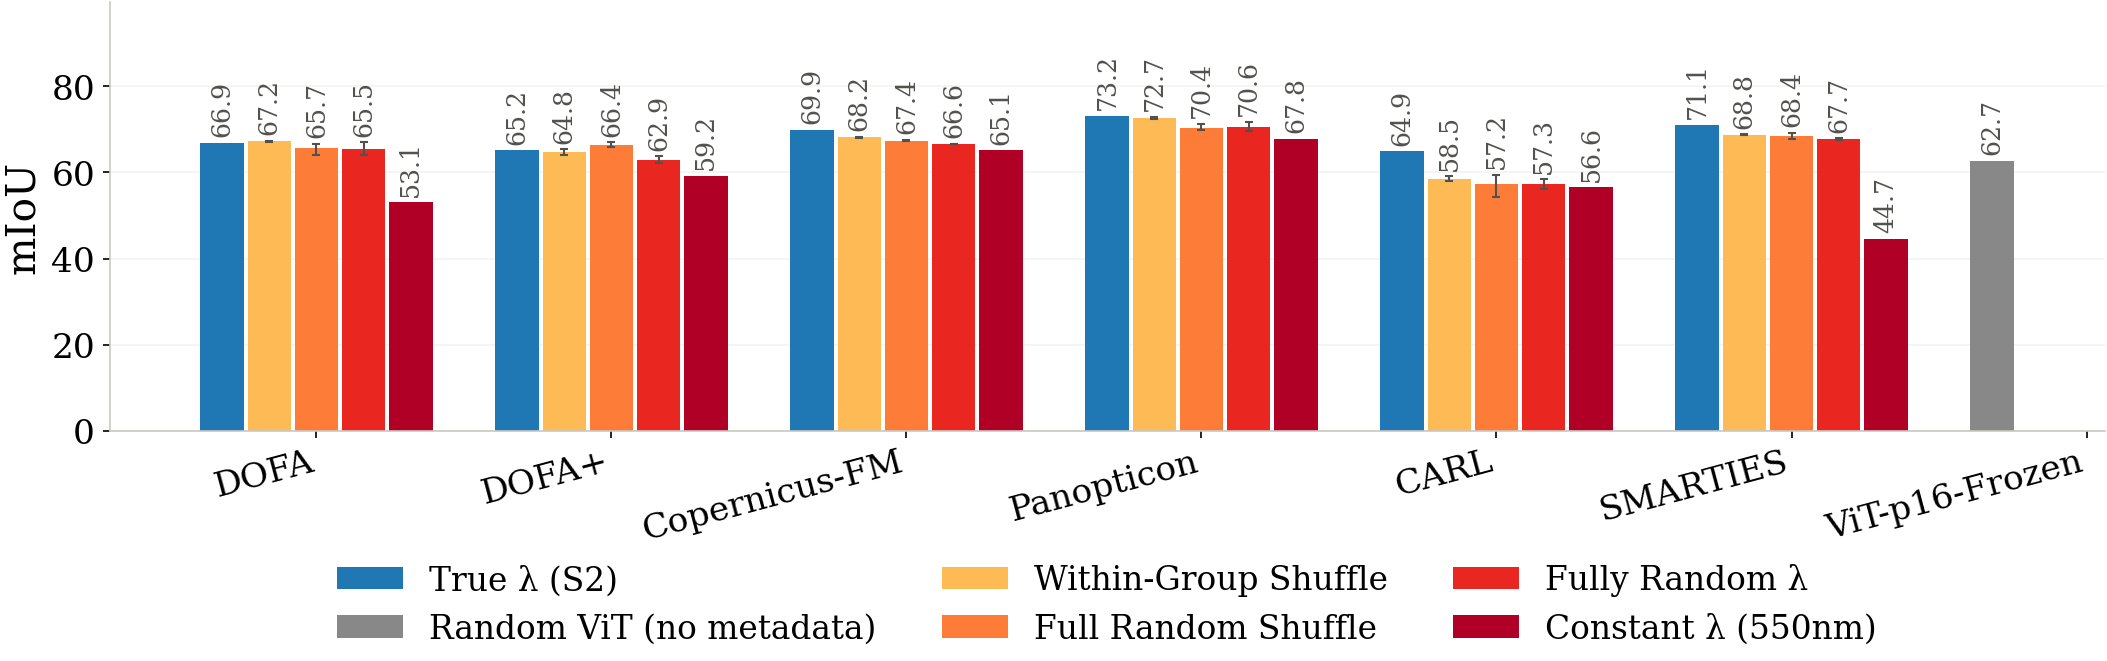

saved figures/wrong_wl_summary_m_sa_crop_type_upernet.pdf


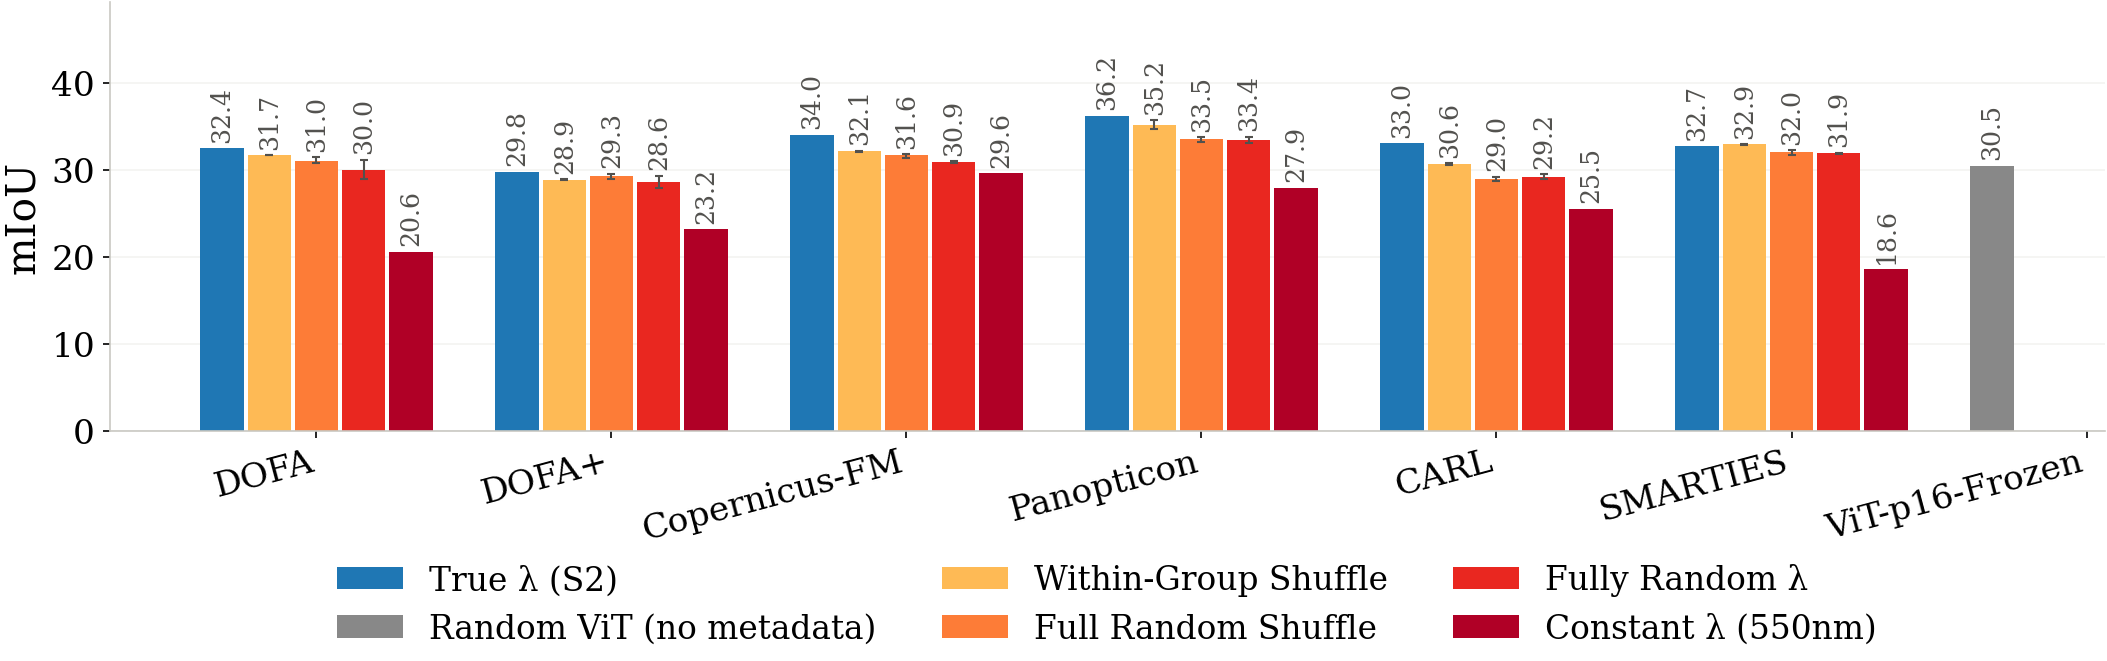

saved figures/wrong_wl_summary_mados_mlp_fusion.pdf


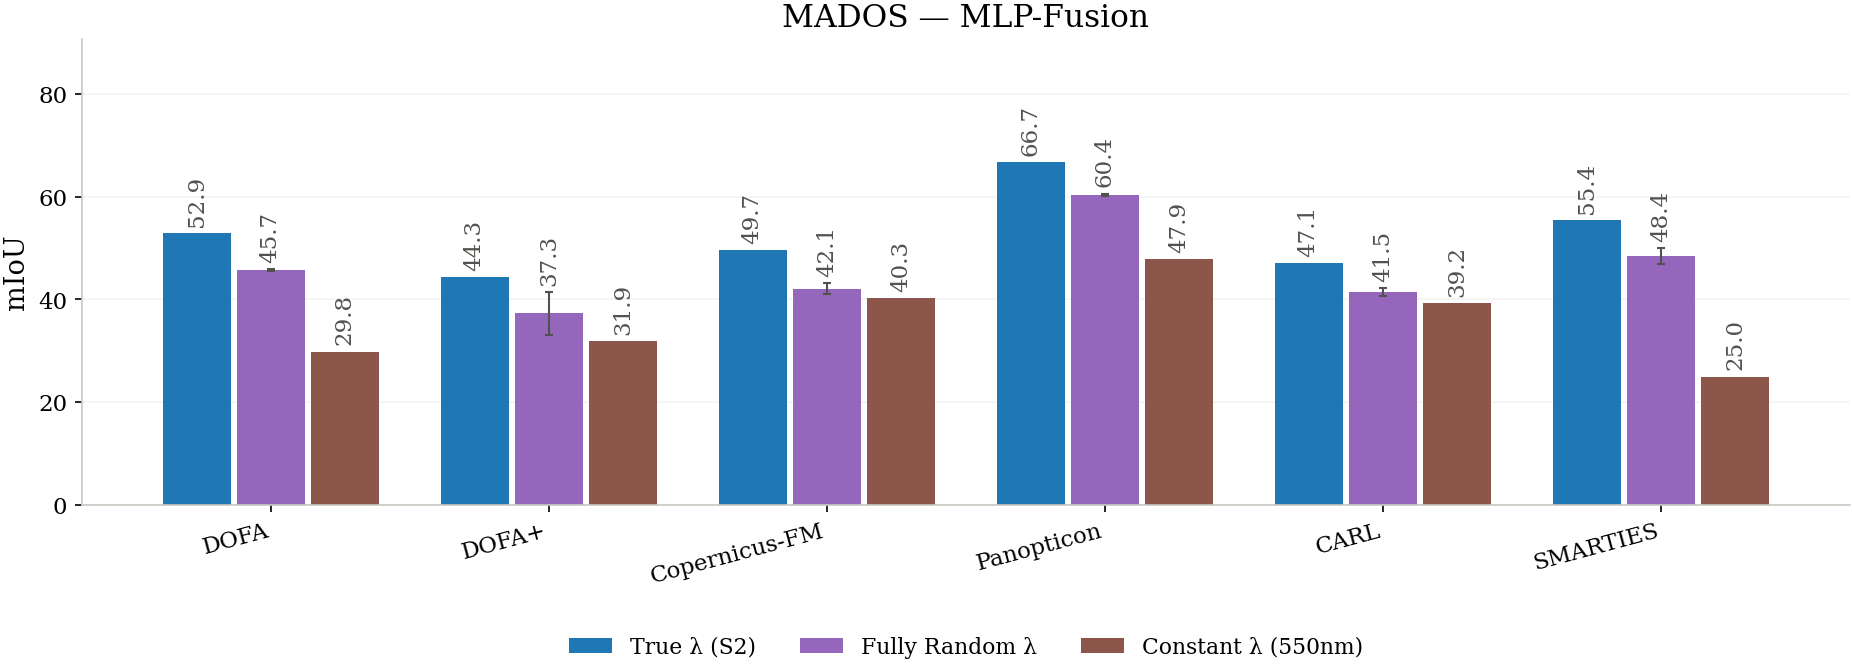

saved figures/wrong_wl_summary_m_cashew_plantation_mlp_fusion.pdf


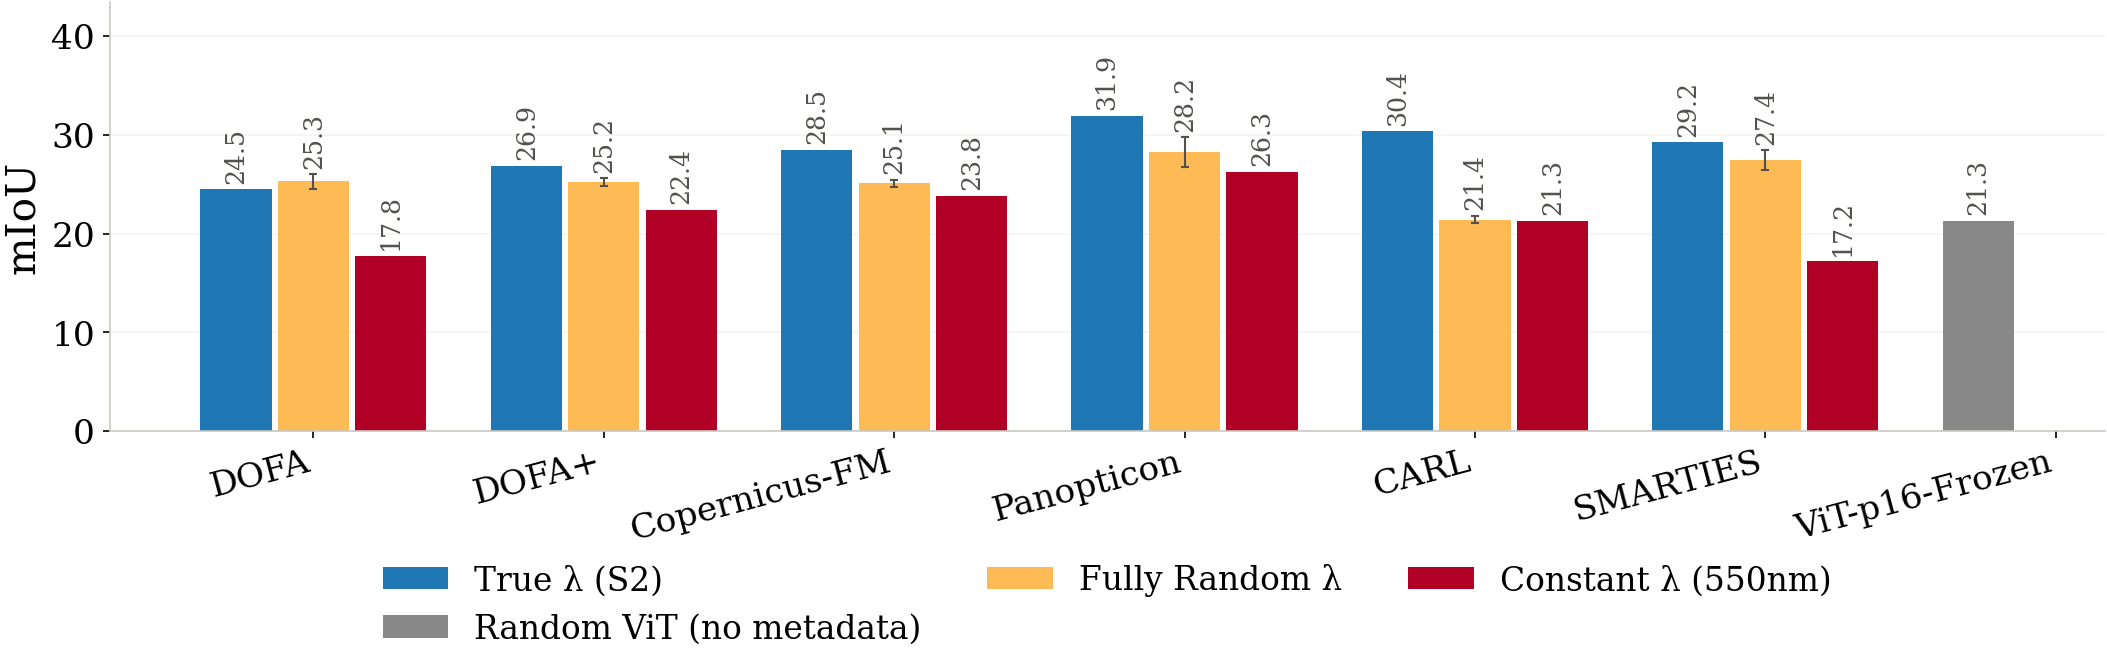

saved figures/wrong_wl_summary_m_sa_crop_type_mlp_fusion.pdf


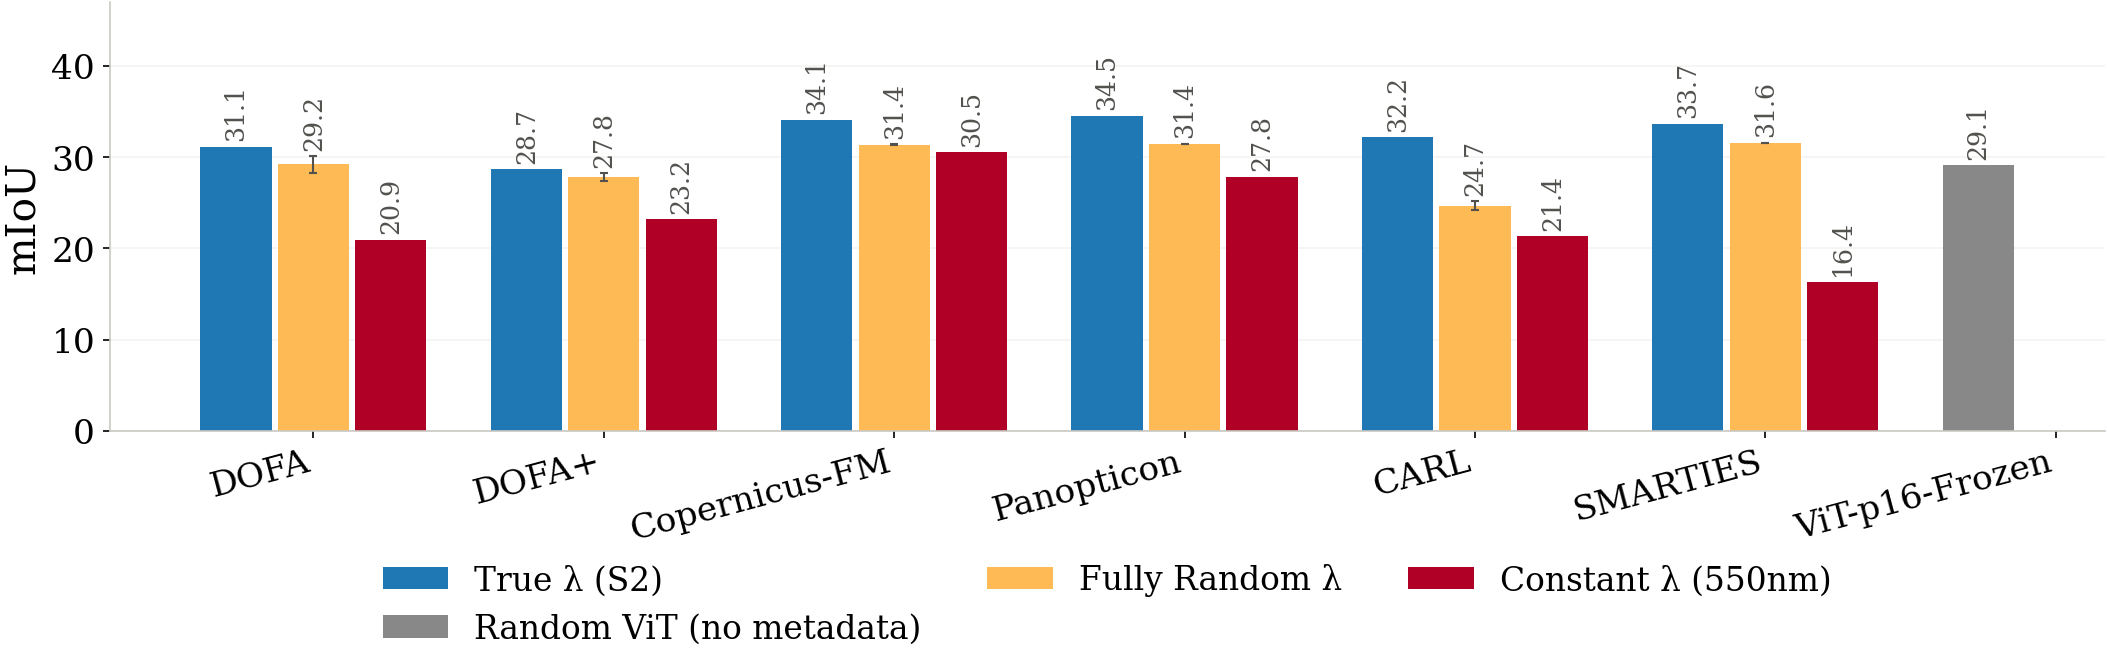

saved figures/wrong_wl_summary_m_forestnet_linear_classification.pdf


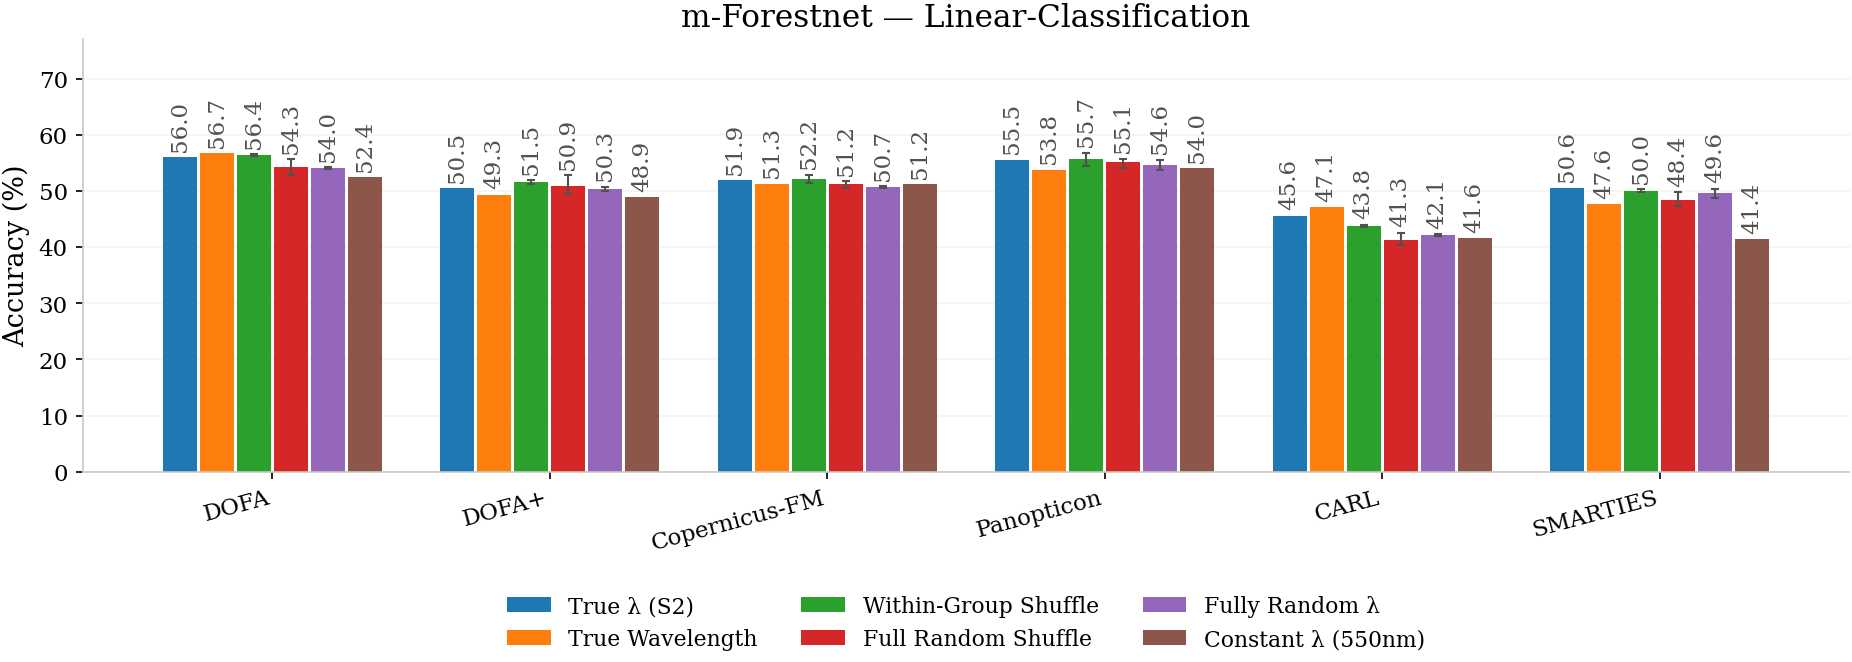

saved figures/wrong_wl_summary_fivebillionpixels_upernet.pdf


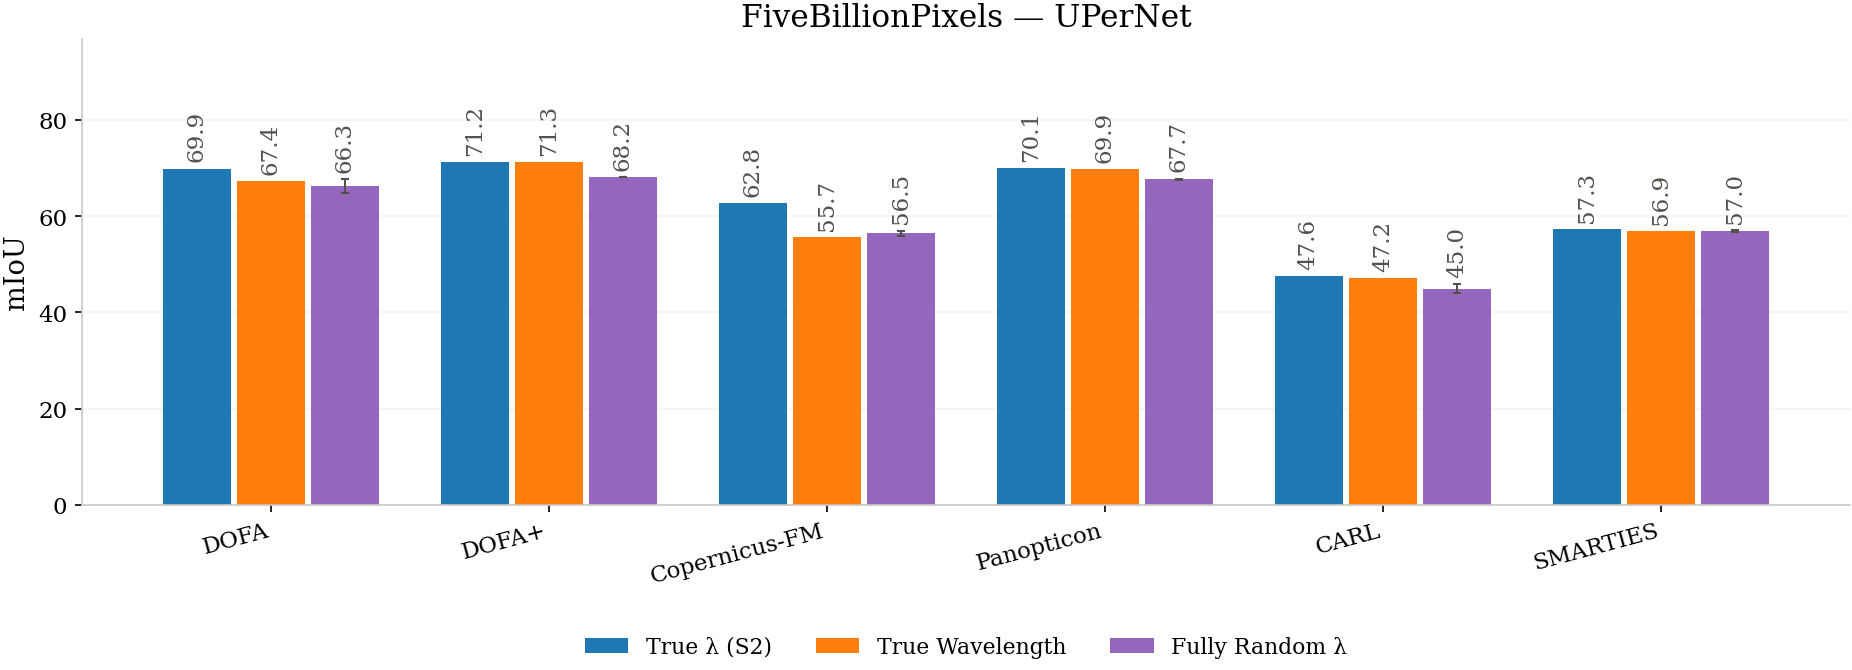

saved figures/wrong_wl_summary_fivebillionpixels_mlp_fusion.pdf


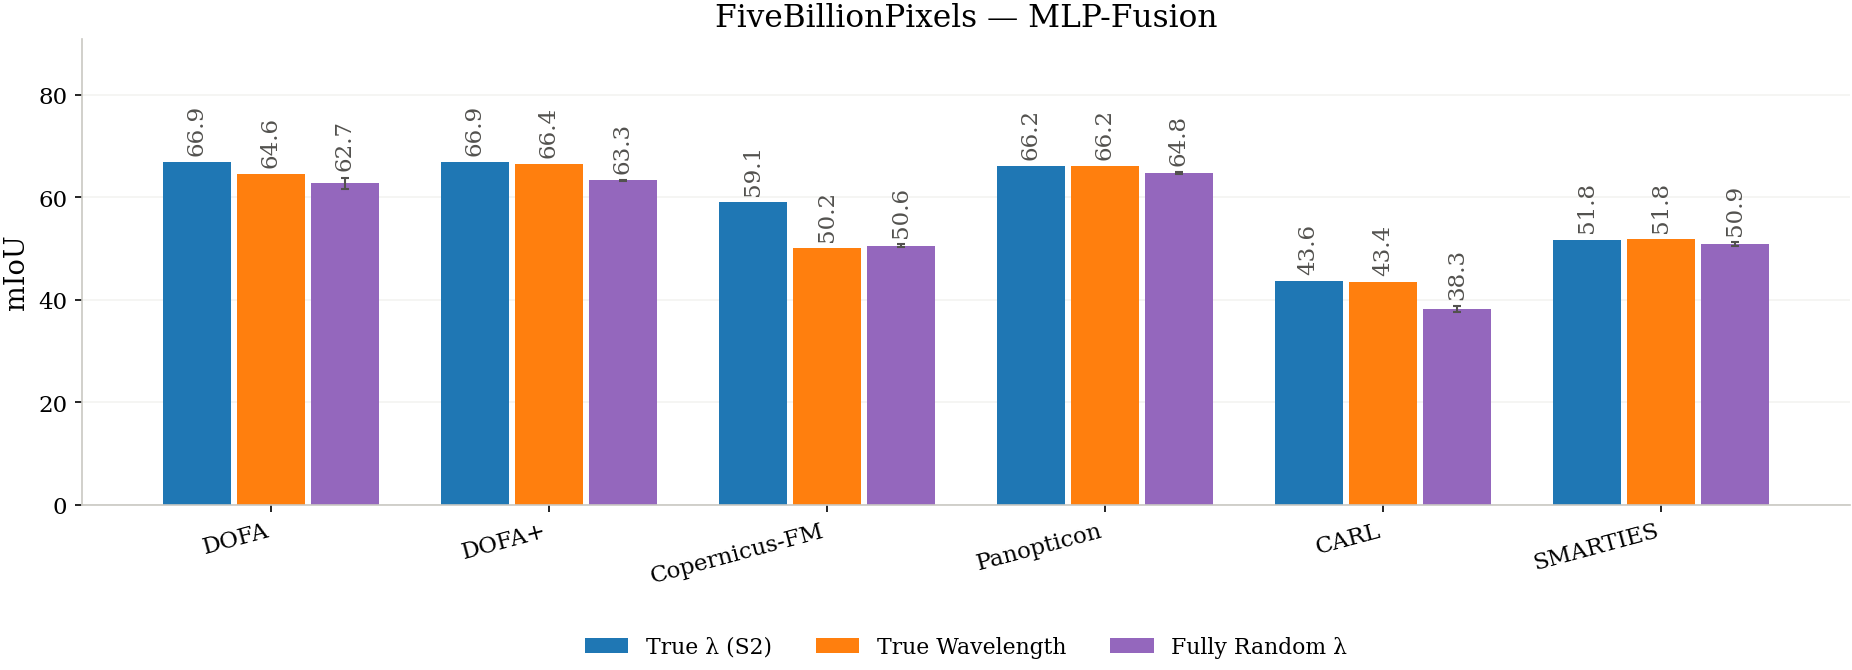

saved figures/wrong_wl_summary_spacenet7_cd_upernet.pdf


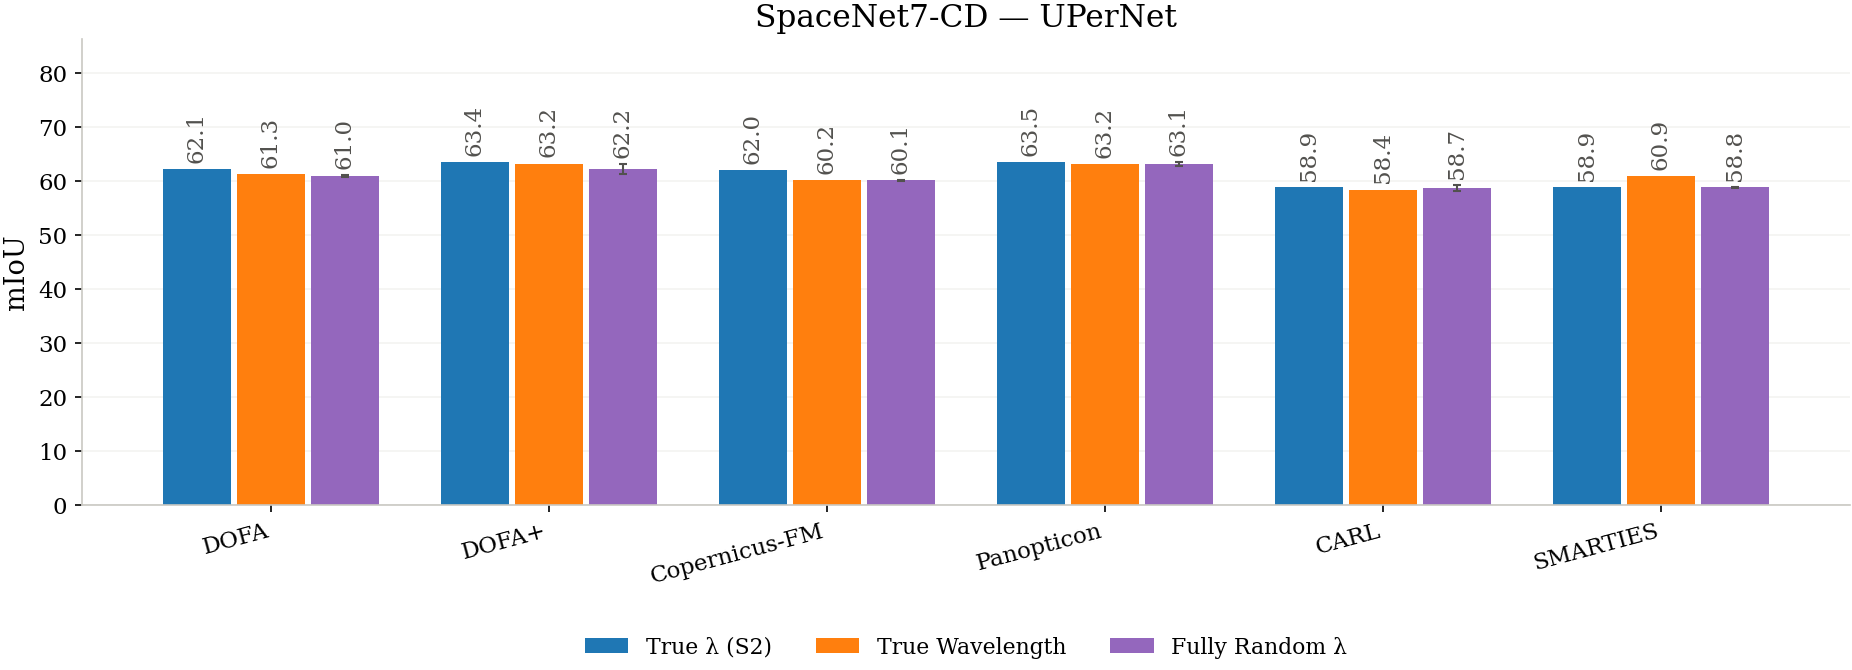

saved figures/wrong_wl_summary_spacenet7_cd_mlp_fusion.pdf


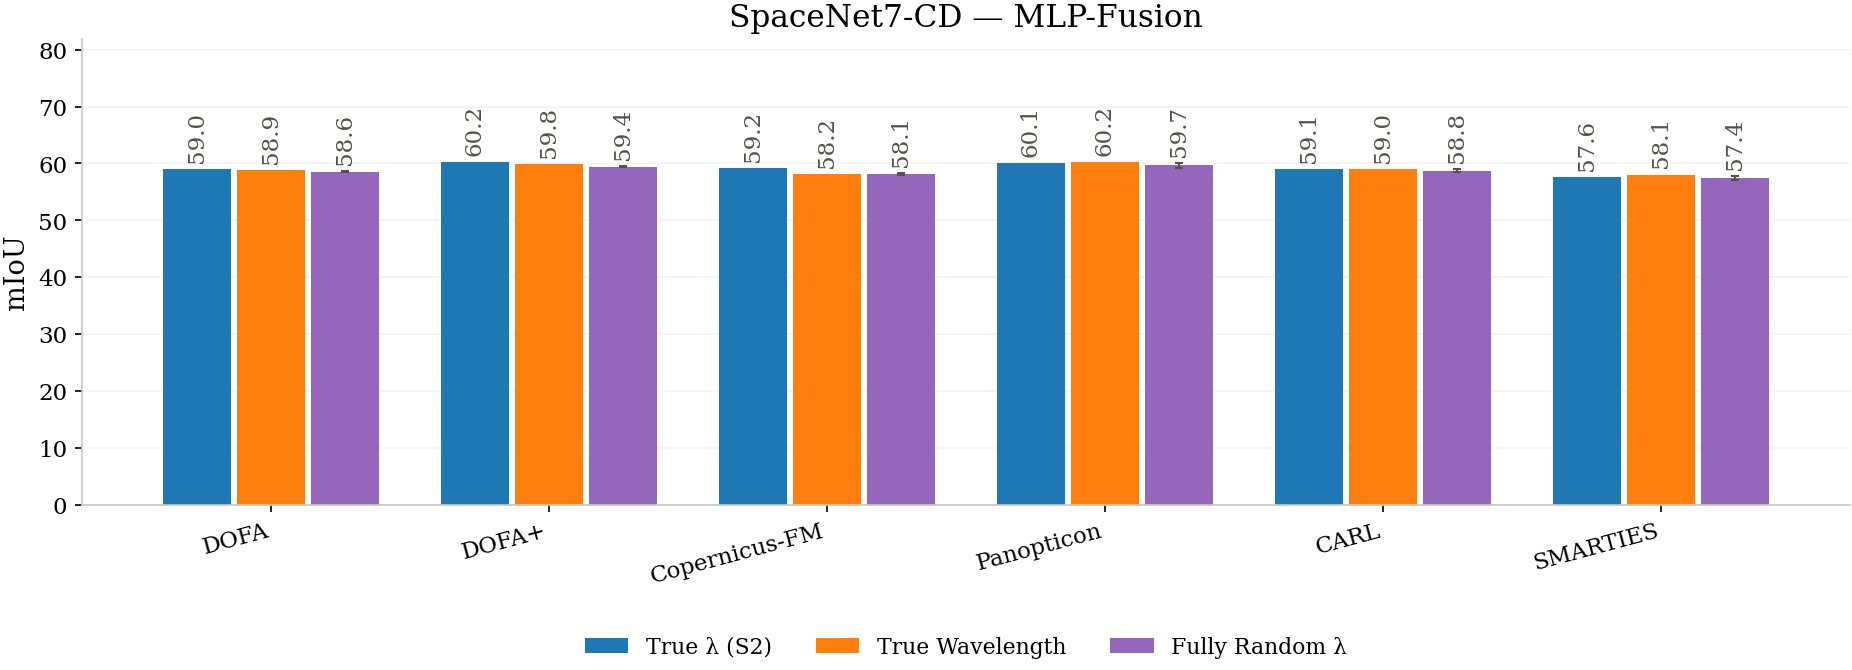

In [8]:
def get_condition_value(dataset: str, decoder: str, encoder: str, condition: str):
    """Returns (mean, lower_err, upper_err) for one (dataset, decoder, encoder, condition),
    computed straight from the raw per-draw rows in df_all (mirrors the sibling
    his-bench_dev notebook's get_condition_value)."""
    sub = df_all[(df_all["dataset"] == dataset) & (df_all["decoder"] == decoder)
                 & (df_all["encoder"] == encoder) & (df_all["condition"] == condition)]
    v = sub["metric"].dropna()
    if len(v) == 0:
        return (np.nan, 0.0, 0.0)
    m = v.mean()
    return (m, m - v.min(), v.max() - m)


BASELINE_CONDITIONS = {"True λ (S2)", "True Wavelength"}


def plot_comparison(dataset: str, decoder: str, encoders: list[str] | None = None,
                     conditions: list[str] | None = None, fname_suffix: str = "",
                     ax: plt.Axes | None = None, title: str | None = None,
                     colors: dict[str, str] | None = None, colors_from_front: bool = False,
                     severity_colors: bool = False, fontsize_scale: float = 1.0,
                     value_fontsize_scale: float | None = None,
                     special_bar_color: dict[str, str] | None = None,
                     special_bar_label: dict[str, str] | None = None):
    """conditions=None (default) auto-detects every condition with data for this
    (dataset, decoder), in CONDITION_ORDER (True λ (S2) first, True Wavelength
    second, ..., most severe corruption last). Pass an explicit subset (e.g. just
    the 3-way True-λ(S2) / True-Wavelength / Fully-Random-λ comparison) to restrict
    the chart even when more conditions exist -- the given order is preserved
    either way, not re-sorted.

    colors=None (default): uses CONDITION_COLORS (bar color fixed by each
    condition's position in CONDITION_ORDER, consistent across every chart in
    this notebook) -- unless colors_from_front=True (palette's colors starting
    from the first one, in this chart's own condition order) or
    severity_colors=True (below) is set. Pass an explicit {condition: color}
    dict via `colors` to override directly instead (e.g. the cross-sensor
    3-way comparison, which fixes the same 3 conditions/colors across all 3
    panels regardless of what's present per panel).

    severity_colors=True: baseline conditions (True λ (S2) / True Wavelength)
    get the same blue used for "True λ (S2)" everywhere else in this notebook
    (CONDITION_COLORS), and every corruption condition gets a color sampled
    from a yellow->orange->red ramp (cmap "YlOrRd") in increasing order of
    severity -- mild corruption pale yellow, most severe deep red. Used by the
    m-Cashew-Plantation / m-SA-Crop-Type combos below so bar color visually
    tracks how corrupted the wavelength label is, while the baseline bar stays
    the same blue as the baseline bar in every other chart.

    special_bar_color / special_bar_label: per-encoder color/legend overrides,
    keyed by encoder name. Used for the ViT-p16-Frozen reference bar: it only
    ever has data for the "True λ (S2)" condition, but since it has no
    wavelength conditioning at all, coloring it the same blue as the real
    True-λ(S2) baseline bars is misleading (review feedback -- it implies it
    uses wavelength metadata when it doesn't). Any encoder listed here gets
    drawn as its own separate bar (own color, own legend entry) instead of
    being lumped into the condition's main colored bar group; does not affect
    bar position/order or any other encoder's bar.

    fontsize_scale=1.0 (default): multiplies the tick/axis-label/title/legend
    font sizes for this chart only (rcParams stay untouched) -- used to bump up
    readability for specific crowded charts (e.g. the m-Cashew-Plantation /
    m-SA-Crop-Type combos below, which also carry the extra ViT-p16-Frozen
    reference bar).

    value_fontsize_scale=None (default): scale specifically for the rotated
    value labels printed above each bar -- falls back to `fontsize_scale` when
    not given. Separated out because the bar-top numbers get crowded/too large
    faster than the rest of the chart as fontsize_scale grows, so a chart can
    scale its ticks/legend up while keeping the bar values more modest.

    title=None (default): auto-generates "dataset — decoder". Pass "" to omit
    the title entirely (used by the m-Cashew-Plantation / m-SA-Crop-Type
    combos below) or any other string to override it.

    ax=None (default): creates its own standalone figure, saves it to
    figures/wrong_wl_summary_<dataset>_<decoder>[_<fname_suffix>].pdf, and shows it.
    ax=<Axes>: draws into that axes instead (no new figure, no save, no show) --
    used to compose several of these into one multi-panel figure, e.g. the
    cross-sensor 3-way comparison below."""
    encoders = encoders or ENCODER_ORDER
    if conditions is None:
        conditions = [
            c for c in CONDITION_ORDER
            if not df_all[(df_all["dataset"] == dataset) & (df_all["decoder"] == decoder)
                          & (df_all["condition"] == c)].empty
        ]
    else:
        conditions = [
            c for c in conditions
            if not df_all[(df_all["dataset"] == dataset) & (df_all["decoder"] == decoder)
                          & (df_all["condition"] == c)].empty
        ]
    if len(conditions) < 2:   # need baseline + at least one perturbation to be worth plotting
        return False

    if colors is None:
        if severity_colors:
            cmap = plt.cm.YlOrRd
            severe = [c for c in conditions if c not in BASELINE_CONDITIONS]
            n = len(severe)
            ramp = [cmap(0.35 + 0.55 * (i / (n - 1))) for i in range(n)] if n > 1 else [cmap(0.75)]
            colors = {c: CONDITION_COLORS["True λ (S2)"] for c in BASELINE_CONDITIONS}
            colors.update({c: ramp[i] for i, c in enumerate(severe)})
        elif colors_from_front:
            _cyc = plt.rcParams["axes.prop_cycle"].by_key()["color"]
            colors = {c: _cyc[i % len(_cyc)] for i, c in enumerate(conditions)}
        else:
            colors = CONDITION_COLORS

    n_cond, n_enc = len(conditions), len(encoders)
    bar_width = 0.8 / n_cond
    x = np.arange(n_enc)

    per_cond = {}
    for condition in conditions:
        vals, los, his = [], [], []
        for enc in encoders:
            m, lo, hi = get_condition_value(dataset, decoder, enc, condition)
            vals.append(m); los.append(lo); his.append(hi)
        per_cond[condition] = (vals, los, his)

    finite_maxes = [np.nanmax(v) for (v, _, _) in per_cond.values() if not np.all(np.isnan(v))]
    y_max = max(0.05, max(finite_maxes) if finite_maxes else 0.05)
    label_pad = y_max * 0.02

    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(1.7 * n_enc + 2.5, 5.0))
    else:
        fig = ax.figure

    special_bar_color = special_bar_color or {}
    special_bar_label = special_bar_label or {}
    special_idx = {enc: j for j, enc in enumerate(encoders) if enc in special_bar_color}

    value_fontsize = 11 * (value_fontsize_scale if value_fontsize_scale is not None else fontsize_scale)
    for i, condition in enumerate(conditions):
        offset = (i - (n_cond - 1) / 2) * bar_width
        vals, los, his = per_cond[condition]
        yerr = np.array([los, his])
        has_err = np.any(yerr > 1e-9)

        normal_idx = [j for j in range(n_enc) if j not in special_idx.values()]
        if normal_idx:
            ax.bar(
                x[normal_idx] + offset, [vals[j] for j in normal_idx], width=bar_width * 0.92,
                color=colors[condition], label=condition,
                yerr=yerr[:, normal_idx] if has_err else None,
                capsize=2, error_kw={"linewidth": 1, "ecolor": TEXT_MUTED},
            )
        # special-cased encoders (e.g. ViT-p16-Frozen): own color, own legend
        # entry, drawn as a separate single-bar call so they never inherit the
        # condition's color/label.
        for enc, j in special_idx.items():
            if np.isnan(vals[j]):
                continue
            ax.bar(
                x[j] + offset, vals[j], width=bar_width * 0.92,
                color=special_bar_color[enc], label=special_bar_label.get(enc, enc),
                yerr=[[los[j]], [his[j]]] if has_err else None,
                capsize=2, error_kw={"linewidth": 1, "ecolor": TEXT_MUTED},
            )

        for xi, v, hi in zip(x + offset, vals, his):
            if np.isnan(v):
                continue
            top = v + (hi if has_err else 0.0)
            ax.text(xi, top + label_pad, f"{v:.1f}", ha="center", va="bottom",
                    fontsize=value_fontsize, rotation=90, color=TEXT_MUTED)

    ax.set_xticks(x)
    ax.set_xticklabels(encoders, rotation=15, ha="right",
                        fontsize=plt.rcParams["xtick.labelsize"] * fontsize_scale)
    ax.tick_params(axis="y", labelsize=plt.rcParams["ytick.labelsize"] * fontsize_scale)
    ax.set_ylabel(METRIC_LABEL.get(dataset, "mIoU"), fontsize=plt.rcParams["axes.labelsize"] * fontsize_scale)
    display_title = title if title is not None else f"{dataset} — {decoder}"
    if display_title:
        ax.set_title(display_title, fontsize=plt.rcParams["axes.titlesize"] * fontsize_scale)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, linewidth=0.8, color=GRID_COLOR)
    ax.set_axisbelow(True)
    ax.set_ylim(0, y_max * 1.36)

    if own_fig:
        ax.legend(frameon=False, ncols=min(n_cond + len(special_idx), 3), loc="upper center",
                  bbox_to_anchor=(0.5, -0.24), fontsize=10.5 * fontsize_scale)
        fig.tight_layout()

        suffix = f"_{_slug(fname_suffix)}" if fname_suffix else ""
        fname = f"wrong_wl_summary_{_slug(dataset)}_{_slug(decoder)}{suffix}.pdf"
        fig.savefig(FIG_DIR / fname, bbox_inches="tight")
        print(f"saved {FIG_DIR / fname}")

        plt.show()
    return True


# m-Cashew-Plantation / m-SA-Crop-Type get ViT-p16-Frozen added back in (it
# shows up as a flat "True λ (S2)"-only reference bar -- no wavelength
# conditioning at all, so every corruption condition is a no-op for it and was
# never run), a larger font scale (bar-top value labels scaled more modestly
# than the rest -- they got crowded/too large at the full fontsize_scale),
# severity-ramp colors (blue baseline, yellow->orange->red for increasingly
# corrupted conditions), and no title -- per explicit request. ViT-p16-Frozen's
# bar is drawn grey with its own legend entry ("Random ViT (no metadata)")
# rather than inheriting the True-λ(S2) baseline's blue -- it has no wavelength
# conditioning at all, so sharing that color/label would misleadingly imply it
# uses wavelength metadata (review feedback). Every other combo keeps the
# default 6-encoder set, notebook-wide font sizes, CONDITION_ORDER-positional
# colors, and the auto-generated title.
EXTENDED_ENCODERS = ENCODER_ORDER + ["ViT-p16-Frozen"]
EXTRA_FONT_DATASETS = {"m-Cashew-Plantation", "m-SA-Crop-Type"}
VIT_SPECIAL_COLOR = {"ViT-p16-Frozen": "#888888"}
VIT_SPECIAL_LABEL = {"ViT-p16-Frozen": "Random ViT (no metadata)"}

COMBOS = [
    ("MADOS", "UPerNet"), ("m-Cashew-Plantation", "UPerNet"), ("m-SA-Crop-Type", "UPerNet"),
    ("MADOS", "MLP-Fusion"), ("m-Cashew-Plantation", "MLP-Fusion"), ("m-SA-Crop-Type", "MLP-Fusion"),
    ("m-Forestnet", "Linear-Classification"),
    ("FiveBillionPixels", "UPerNet"), ("FiveBillionPixels", "MLP-Fusion"),
    ("SpaceNet7-CD", "UPerNet"), ("SpaceNet7-CD", "MLP-Fusion"),
]
for ds, dec in COMBOS:
    if ds in EXTRA_FONT_DATASETS:
        ok = plot_comparison(ds, dec, encoders=EXTENDED_ENCODERS, fontsize_scale=1.5,
                              value_fontsize_scale=1.1, severity_colors=True, title="",
                              special_bar_color=VIT_SPECIAL_COLOR, special_bar_label=VIT_SPECIAL_LABEL)
    else:
        ok = plot_comparison(ds, dec)
    if not ok:
        print(f"skipped {ds} / {dec} -- insufficient data")


## Cross-sensor 3-way comparison — SpaceNet7-CD, FiveBillionPixels, Landsat-8 (m-Forestnet)

These are the only 3 datasets where the S2-default label isn't actually correct, so each gets a genuine
three-way comparison — **True λ (S2)** vs. **True Wavelength** (the sensor's own real center wavelengths)
vs. **Fully Random λ** — combined into one figure, one panel per dataset, sharing a single legend. Bar
order within every panel is fixed: S2 first, True Wavelength second, Fully Random λ last.

SpaceNet7-CD and FiveBillionPixels also have an MLP-Fusion decoder (already shown separately above); this
combined view uses UPerNet for both, matching m-Forestnet's decoder-agnostic `cls_linear` probe so all
three panels sit on the same footing.

saved figures/wrong_wl_summary_cross_sensor_3way.pdf


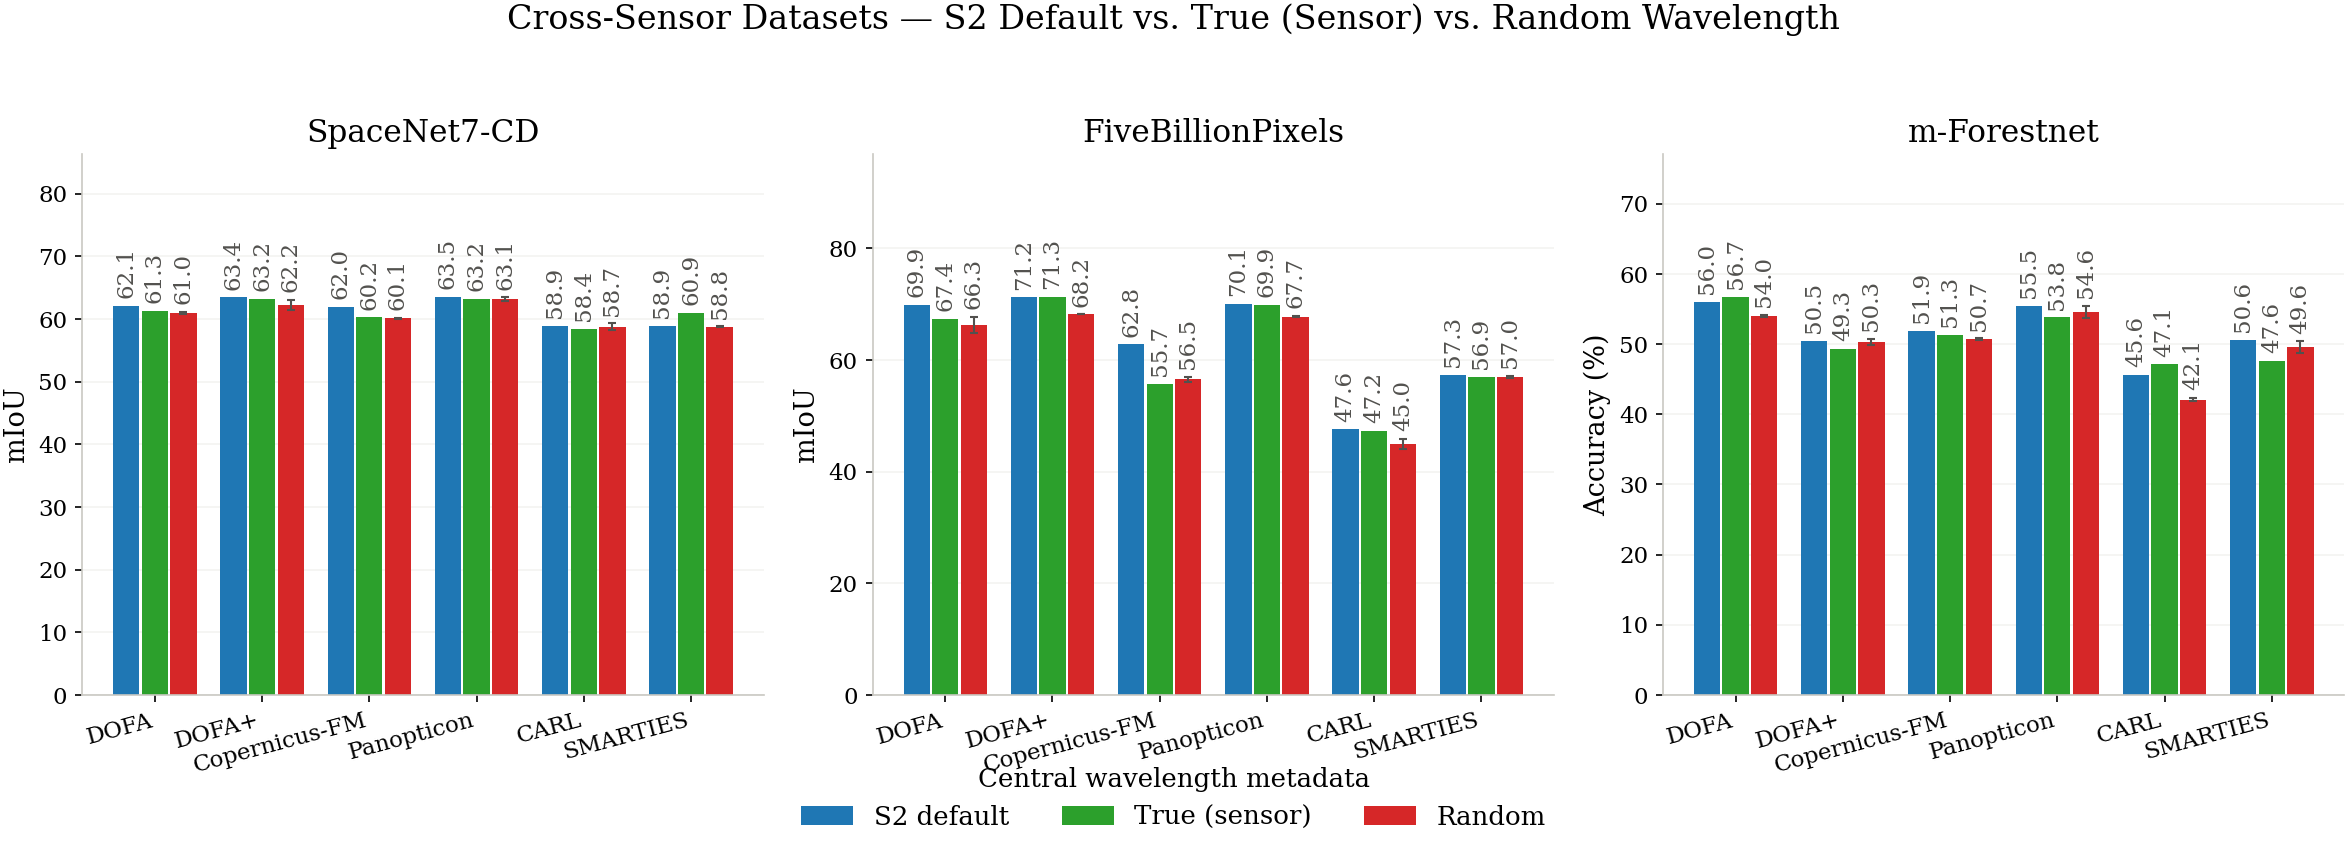

In [9]:
CROSS_SENSOR_3WAY = [
    ("SpaceNet7-CD", "UPerNet"),
    ("FiveBillionPixels", "UPerNet"),
    ("m-Forestnet", "Linear-Classification"),
]
THREE_WAY_CONDITIONS = ["True λ (S2)", "True Wavelength", "Fully Random λ"]

# Explicit semantic colors (requested by supervisor review): blue = S2 default,
# green = true (sensor-native) wavelengths, red = random -- NOT the first 3
# colors of the shared cycle (which would put "Fully Random λ" on orange, not
# red, and "True Wavelength" on orange too, no green at all).
THREE_WAY_COLORS = {
    "True λ (S2)":     "#1f77b4",  # blue
    "True Wavelength": "#2ca02c",  # green
    "Fully Random λ":  "#d62728",  # red
}

# Display-only legend relabeling: the underlying condition strings (used for
# data lookups everywhere else in this notebook) are unchanged -- only the
# legend text shown here is renamed. "True wavelength (S2)" was flagged as
# confusing in review, since the Sentinel-2 values are not the true/native
# wavelengths of these sensors; the renamed labels make the S2-vs-true
# distinction explicit, and the legend title clarifies that all three refer to
# central-wavelength metadata (not the pixel data, which is identical across
# all three conditions).
THREE_WAY_LEGEND_LABELS = {
    "True λ (S2)":     "S2 default",
    "True Wavelength": "True (sensor)",
    "Fully Random λ":  "Random",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))

for ax, (ds, dec) in zip(axes, CROSS_SENSOR_3WAY):
    plot_comparison(ds, dec, conditions=THREE_WAY_CONDITIONS, ax=ax, title=ds, colors=THREE_WAY_COLORS)

# one shared legend below all 3 panels, in THREE_WAY_CONDITIONS order
handles, labels = axes[0].get_legend_handles_labels()
legend_labels = [THREE_WAY_LEGEND_LABELS.get(l, l) for l in labels]
fig.legend(handles, legend_labels, frameon=False, ncols=3, loc="lower center",
           bbox_to_anchor=(0.5, -0.06), fontsize=12.5, title="Central wavelength metadata",
           title_fontsize=12.5)
# Title updated to match the renamed legend entries above (S2 default / True
# (sensor) / Random) instead of the raw internal condition strings.
fig.suptitle("Cross-Sensor Datasets — S2 Default vs. True (Sensor) vs. Random Wavelength", y=1.03, fontsize=16)
fig.tight_layout()

_fname = "wrong_wl_summary_cross_sensor_3way.pdf"
fig.savefig(FIG_DIR / _fname, bbox_inches="tight")
print(f"saved {FIG_DIR / _fname}")

plt.show()